## **Double gyre flow**


In [7]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [8]:
import mikeio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import modelskill as ms
import torch

from ipywidgets import interact, FloatSlider, IntSlider
import matplotlib.patches as patches

import sys
from pathlib import Path

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent.parent))

from src.datamanager import ROMDataManager
from src.engine import SHREDEngine
from src.train import fit, evaluate
from src.mSHRED.mSRED import mSHRED

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# additional imports for DGF
from helpers import DGFsimulation


## Solver

Shape of U:	 (200, 101, 1250) 	Shape of Uraw:	 (200, 101, 50, 25)
Shape of V:	 (200, 101, 1250) 	Shape of Vraw:	 (200, 101, 50, 25)
measurements:	 (200, 101, 3)


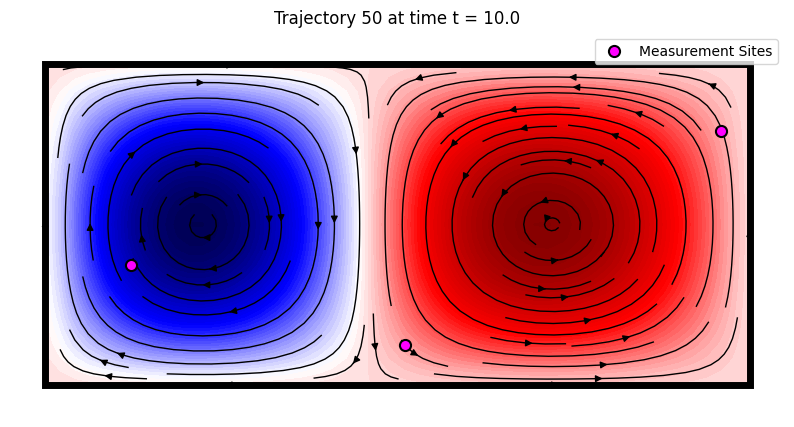

In [9]:
# generate DGF data 
simulator    = DGFsimulation(ntrajectories=200)
Uraw, Vraw   = simulator.generate_data()
U,     V     = simulator.get_reshaped_data()
measurements = simulator.generate_measurements_U(nsensors=3)

# Debugging 
print("Shape of U:\t", U.shape, "\tShape of Uraw:\t", Uraw.shape)
print("Shape of V:\t", V.shape, "\tShape of Vraw:\t", Vraw.shape)
print("measurements:\t", measurements.shape)
simulator.plot_data(which_trajectory=50)

## DataManager

In [10]:
# Data manager
lags = 25
manager = ROMDataManager(lags = lags, train_size = 0.8, val_size = 0.1, test_size = 0.1)

# add data to manager
manager.add_data(U, id = "U" , compress = 5, measurements = measurements)
manager.add_data(V, id = "V" , compress = 5)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True)

# Debugging: check input and output shapes for the model
nn_input_shape = train_dataset[0][0].shape[1]  # input shape is the number of measurements
nn_output_shape = train_dataset[0][1].shape[0]  # output shape is the compressed (SVD) dimension
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

Residual energy of U after keeping 5 modes: 0.0000 %
Residual energy of V after keeping 5 modes: 0.0000 %

Datasets: ['U', 'V']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([16160, 25, 3]) -> torch.Size([16160, 10])
Val:	 torch.Size([2020, 25, 3]) -> torch.Size([2020, 10])
Test:	 torch.Size([2020, 25, 3]) -> torch.Size([2020, 10])

Input shape for the model: 3
Output shape for the model: 10


In [11]:
ERRORS = []

# T.0

In [ ]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=1, input_size=nn_input_shape, n_heads=4,
    dim_feedforward=64, hidden_size=32, input_length=lags, double_channels = False,
    # Decoder
    decoder="mlp", decoder_hidden_sizes=[], output_size=nn_output_shape, dropout=0.1,
)
mshred = mSHRED(args=model_args).to(device)

train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer="AdamW", lr=1e-3, num_epochs=300, lr_scheduler="CosineAnnealingLR", scheduler_step_size=300, patience=60, verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset)
val_mse, val_mre = evaluate(mshred, val_dataset)
test_mse, test_mre = evaluate(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(T.0) only available sensors",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Starting training...


Training:   6%|▋         | 19/300 [01:28<12:58,  2.77s/it, Train Loss=0.0295, Val Loss=0.0359, Patience=1, Best Val Loss=0.0373, LR=9.90e-04] 

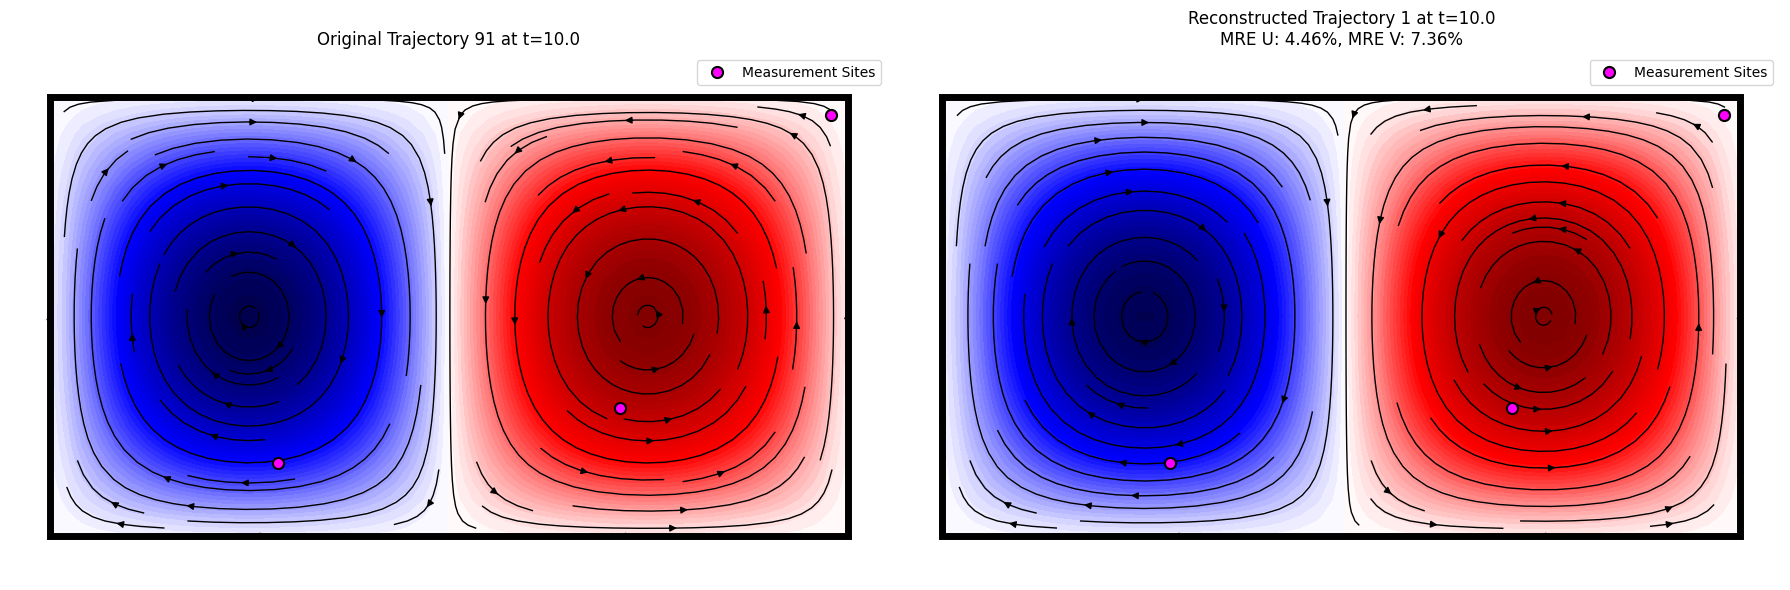

In [ ]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
simulator.plot_comparison(test_reconstruction, manager.test_indices, which_trajectory=1)